In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
#import data
df=pd.read_excel("SQL,Python,powerbi Project data.xlsx")

In [24]:
df.head(20)

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually
5,6,46,Male,Sneakers,Footwear,20,Wyoming,M,White,Summer,2.9,Yes,Standard,Yes,Yes,14,Venmo,Weekly
6,7,63,Male,Shirt,Clothing,85,Montana,M,Gray,Fall,3.2,Yes,Free Shipping,Yes,Yes,49,Cash,Quarterly
7,8,27,Male,Shorts,Clothing,34,Louisiana,L,Charcoal,Winter,3.2,Yes,Free Shipping,Yes,Yes,19,Credit Card,Weekly
8,9,26,Male,Coat,Outerwear,97,West Virginia,L,Silver,Summer,2.6,Yes,Express,Yes,Yes,8,Venmo,Annually
9,10,57,Male,Handbag,Accessories,31,Missouri,M,Pink,Spring,4.8,Yes,2-Day Shipping,Yes,Yes,4,Cash,Quarterly


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [26]:
df.describe(include="all")

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [27]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [28]:
#fill all nan values with median of each category
df['Review Rating']=df.groupby('Category')['Review Rating'].transform(lambda x:x.fillna(x.median()))

In [29]:
#now check that the missing values are fill now or not
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [30]:
#case snaking: means convert all the names of the column into lowercase and replace the spaces with underscore(_)
#it makes the code easy to read and consistent, and easy for referencing

#convert into lowercase
df.columns=df.columns.str.lower()
#replace spaces with underscore
df.columns=df.columns.str.replace(" ","_")

#Rename a column
df=df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})


In [31]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [32]:
#Some feature enginnering 
#Make a new column known as "AGE GROUP" and "purchase_frequency_days"

label=['Young Adult','Adult','Middle Aged','Senior']
df['age_group']=pd.qcut(df['age'], q=4, labels=label)


In [33]:
df[['age','age_group']].head(10)

,age,age_group
0,55,Middle Aged
1,19,Young Adult
2,50,Middle Aged
3,21,Young Adult
4,45,Middle Aged
5,46,Middle Aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle Aged


In [34]:
#create purchase_frequency_days column
frequency_mapping={
    'Fortnightly':14,
    'Weekly':7,
    'Monthly':30,
    'Quarterly':90,
    'Bi-Weekly':14,
    'Annually':30,
    'Every 3 Months':90
}

df['purchase_frequency_days']=df['frequency_of_purchases'].map(frequency_mapping)
    


In [35]:
df[['purchase_frequency_days','frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,30,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,30,Annually
9,90,Quarterly


In [36]:
#Check the column that their values are exactly same or not

(df['discount_applied']==df['promo_code_used']).all()


np.True_

In [37]:
#As both columns have exact same values so we drop one column
df=df.drop('promo_code_used',axis=1)

In [38]:
#Check is it remove or not
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='object')

In [39]:
# Create Customer Segment column using frequency

df['Customer_Segment'] = df['frequency_of_purchases'].map({
    'Weekly': 'Loyal',
    'Bi-Weekly': 'Loyal',
    'Fortnightly': 'Loyal',

    'Monthly': 'Returning',
    'Every 3 Months': 'Returning',
    'Quarterly': 'Returning',

    'Annually': 'New'
})

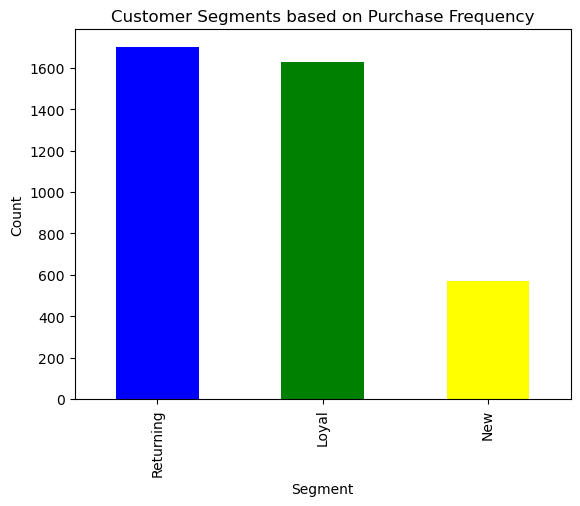

In [40]:
import matplotlib.pyplot as plt

df['Customer_Segment'].value_counts().plot(kind='bar',color=['Blue','Green','Yellow'] )

plt.title("Customer Segments based on Purchase Frequency")
plt.xlabel("Segment")
plt.ylabel("Count")

plt.show()

In [42]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days',
       'Customer_Segment'],
      dtype='object')

In [ ]:
# Group revenue by customer type
revenue_data = df.groupby('subscription_status')['purchase_amount'].sum()

# Plot bar chart
revenue_data.plot(kind='bar',color=['Green','Blue'])

plt.title('Revenue by Subscription Status')
plt.xlabel('subscription_status')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.show()

In [ ]:
avg_purchase = df.groupby('discount_applied')['purchase_amount'].mean()

In [ ]:
avg_purchase.plot(kind='bar')

plt.title('Average Purchase by Discount Usage')
plt.xlabel('Discount Usage')
plt.ylabel('Average Purchase Amount')
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Define high-value customers
high_value = df[df['purchase_amount'] > df['purchase_amount'].mean()]

# Check how many used discount
high_value['discount_applied'].value_counts().plot(kind='bar')

plt.title('High-Value Customers Using Discounts')
plt.xlabel('Discount Usage')
plt.ylabel('Number of Customers')

plt.show()

In [ ]:
# Group revenue by customer type
revenue_data = df.groupby('item_purchased')['purchase_amount'].sum().sort_values(ascending=False).head(6)

# Plot bar chart
revenue_data.plot(kind='bar',color=['yellow','Blue','green','red','purple','orange'])

plt.title('Top Selling product')
plt.xlabel('Products')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.show()

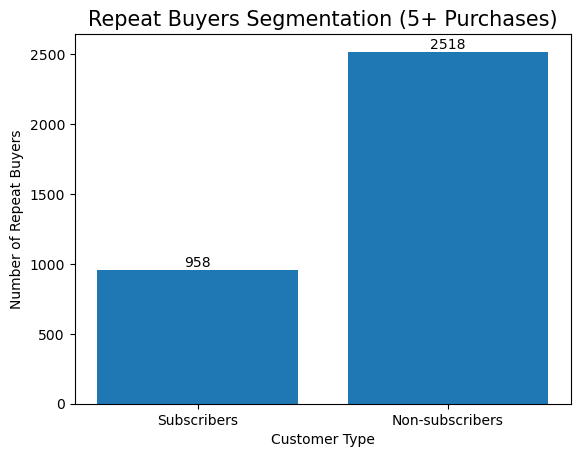

In [50]:
import matplotlib.pyplot as plt

# Data (repeat buyers split)
labels = ['Subscribers', 'Non-subscribers']
values = [958, 2518]  # 3476 total repeat buyers

# Create chart
plt.figure()
bars = plt.bar(labels, values)

# Titles and labels
plt.title('Repeat Buyers Segmentation (5+ Purchases)',fontsize=15)
plt.xlabel('Customer Type')
plt.ylabel('Number of Repeat Buyers')

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, int(height),
             ha='center', va='bottom')

# Save image
plt.savefig('repeat_buyers_chart.png', bbox_inches='tight')

# Show chart
plt.show()

### Now our data is clean and ready for Analysis , so now we can analysis data using any source like Excel,SQL or Python

# Connect notebook with Mysql

In [ ]:
!pip install mysql-connector-python
!pip install pandas
!pip install sqlalchemy


In [ ]:

import pandas as pd
from sqlalchemy import create_engine
import mysql.connector



In [ ]:
#CHECK THAT TABLE IS CREATED IN SQL TO ACCESS DATA 
import sqlalchemy

inspector = sqlalchemy.inspect(engine)
print(inspector.get_table_names())


In [ ]:
#we can clearly see that a table is created in MYSQL 
pd.read_sql("SELECT* FROM customer  LIMIT 5;",engine)